<a href="https://colab.research.google.com/github/Ascavalc/Floripa/blob/main/Aula_16_KNN_SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 16 — Sistema de recomendação com KNN e SVD

Uma pessoa avaliou alguns filmes, mas não todos. Como escolher o que sugerir em seguida? Nesta aula, vamos resolver essa pergunta de duas maneiras. O **KNN** procura pessoas com históricos parecidos. O **SVD** encontra padrões compartilhados na matriz de avaliações. Os dois recebem os mesmos registros de treino e enfrentam o mesmo teste.

A base didática contém 2.000 usuários fictícios e 48 títulos reais, organizados em oito categorias. As notas são simuladas. As preferências usadas para criá-las não são entregues aos modelos. Mantenha os dois CSVs ao lado deste notebook ou envie-os ao Colab quando solicitado. Execute as células na ordem.

Também retomaremos os centros do K-means para construir uma referência por grupo e verificar o que a personalização acrescenta.

In [1]:
# Se necessário: %pip install numpy pandas matplotlib scikit-learn threadpoolctl
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits

pd.set_option('display.max_colwidth', 70)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
arquivos = ['Aula_16_Filmes.csv', 'Aula_16_Avaliacoes.csv']
if not all(Path(a).exists() for a in arquivos):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError('Coloque os dois CSVs na mesma pasta do notebook.')
filmes = pd.read_csv(arquivos[0], sep=';', encoding='utf-8-sig')
avaliacoes = pd.read_csv(arquivos[1], sep=';', decimal=',', encoding='utf-8-sig')
display(filmes.head(6))
display(avaliacoes.head())

,filme_id,titulo,categoria
0,F001,Toy Story,Animação
1,F002,Procurando Nemo,Animação
2,F003,Os Incríveis,Animação
3,F004,Ratatouille,Animação
4,F005,Divertida Mente,Animação
5,F006,Viva: A Vida é uma Festa,Animação


,usuario_id,filme_id,ordem,nota
0,U0001,F037,1,4.50
1,U0001,F041,2,4.50
2,U0001,F001,3,2.00
3,U0001,F008,4,4.50
4,U0001,F022,5,5.00


## 1. Reconhecer a base

Cada linha da tabela de avaliações registra uma nota de um usuário para um filme. `ordem` representa a sequência simulada dessas avaliações. O catálogo guarda nomes e categorias para descrever as recomendações; a categoria não entra como resposta pronta no KNN ou no SVD.

In [2]:
print('Categorias e quantidade de filmes:')
display(filmes.groupby('categoria').size().rename('Filmes').to_frame())
print('Linhas brutas:',len(avaliacoes))
display(avaliacoes.isna().sum().rename('Campos ausentes').to_frame())
print('IDs de avaliação repetidos:',avaliacoes.duplicated(['usuario_id','filme_id']).sum())

Categorias e quantidade de filmes:


,Filmes
categoria,
Animação,6
Aventura,6
Ação,6
Comédia,6
Drama,6
Ficção científica,6
Romance,6
Terror,6


Linhas brutas: 80020


,Campos ausentes
usuario_id,12
filme_id,0
ordem,0
nota,400


IDs de avaliação repetidos: 21


## 2. Preparar os registros

Corrigimos tipos e retiramos linhas sem nota, notas fora de 1 a 5, filmes inexistentes e pares repetidos de usuário e filme. Não substituímos uma nota ausente: ela é justamente a resposta que seria preciso conhecer. Notas 1 e 5 são válidas, mesmo quando aparecem nas pontas do boxplot.

Registros removidos: 464
Avaliações válidas: 79,556
Usuários: 2,000. Filmes: 48.


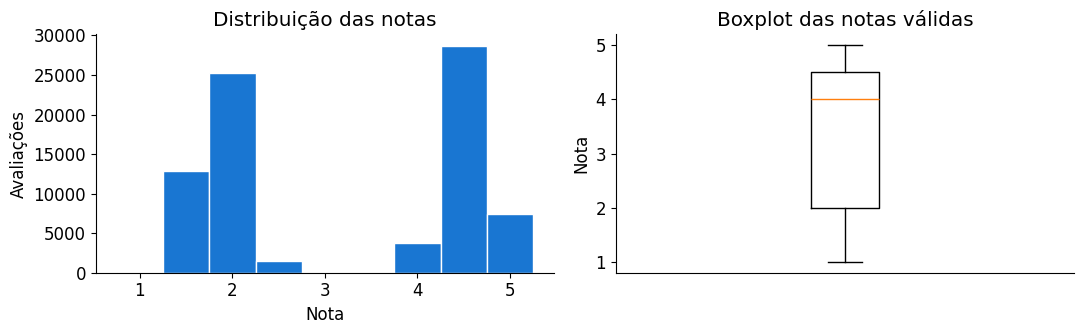

In [3]:
antes = len(avaliacoes)
for coluna in ['usuario_id', 'filme_id']:
    avaliacoes[coluna] = avaliacoes[coluna].astype('string').str.strip().str.upper()
for coluna in ['nota', 'ordem']:
    avaliacoes[coluna] = pd.to_numeric(avaliacoes[coluna], errors='coerce')
avaliacoes = avaliacoes.dropna().drop_duplicates(['usuario_id', 'filme_id'])
validas = (avaliacoes.usuario_id.str.fullmatch(r'U\d{4}')
           & avaliacoes.filme_id.isin(filmes.filme_id)
           & avaliacoes.nota.between(1, 5)
           & avaliacoes.ordem.between(1, 40)
           & avaliacoes.ordem.mod(1).eq(0))
avaliacoes = avaliacoes.loc[validas].sort_values(['usuario_id', 'ordem']).reset_index(drop=True)
avaliacoes['ordem'] = avaliacoes.ordem.astype(int)
print(f'Registros removidos: {antes-len(avaliacoes):,}')
print(f'Avaliações válidas: {len(avaliacoes):,}')
print(f'Usuários: {avaliacoes.usuario_id.nunique():,}. Filmes: {len(filmes)}.')

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
eixos[0].hist(avaliacoes.nota, bins=np.arange(.75, 5.51, .5), color='#1976D2', edgecolor='white')
eixos[0].set(title='Distribuição das notas', xlabel='Nota', ylabel='Avaliações')
eixos[1].boxplot(avaliacoes.nota)
eixos[1].set(title='Boxplot das notas válidas', ylabel='Nota', xticks=[])
plt.tight_layout()
plt.show()

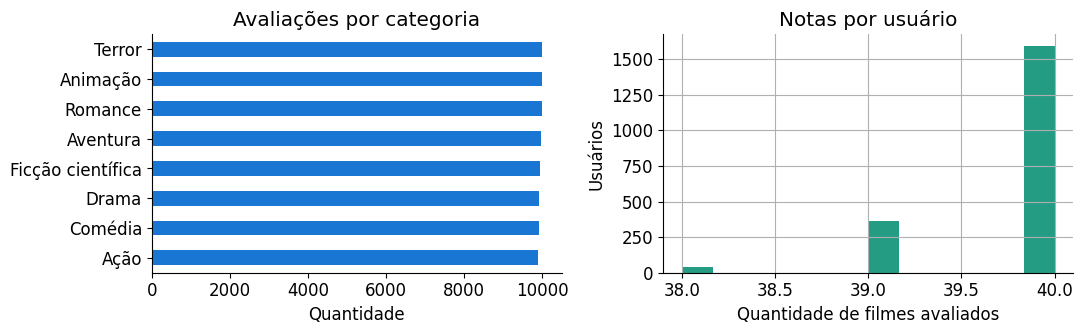

In [4]:
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
contagens=avaliacoes.merge(filmes,on='filme_id').groupby('categoria').size().sort_values()
contagens.plot.barh(ax=ax[0],color='#1976D2')
ax[0].set(title='Avaliações por categoria',xlabel='Quantidade',ylabel='')
avaliacoes.groupby('usuario_id').size().hist(ax=ax[1],bins=12,color='#249C84')
ax[1].set(title='Notas por usuário',xlabel='Quantidade de filmes avaliados',ylabel='Usuários')
plt.tight_layout();plt.show()

## 3. Reservar validação e teste

Para cada pessoa, as avaliações 1 a 24 formam o treino. As de 25 a 28 orientam a escolha de K e da quantidade de fatores. As de 29 a 40 ficam escondidas até a comparação final. Assim, uma boa escolha na validação não é confundida com o resultado no teste.

In [5]:
treino = avaliacoes[avaliacoes.ordem <= 24].copy()
validacao = avaliacoes[avaliacoes.ordem.between(25, 28)].copy()
teste = avaliacoes[avaliacoes.ordem >= 29].copy()
display(pd.DataFrame({'Etapa': ['Treino', 'Validação', 'Teste'],
                      'Avaliações': [len(treino), len(validacao), len(teste)]}))

,Etapa,Avaliações
0,Treino,47732
1,Validação,7958
2,Teste,23866


In [6]:
assert set(treino.index).isdisjoint(validacao.index)
assert set(treino.index).isdisjoint(teste.index)
assert set(validacao.index).isdisjoint(teste.index)
print('Registros de treino, validação e teste não se repetem.')

Registros de treino, validação e teste não se repetem.


## 4. A matriz de notas

Na matriz, a linha é um usuário, a coluna é um filme e a célula é sua nota. Célula vazia significa que ainda não conhecemos aquela opinião. A mesma matriz servirá aos dois métodos. O identificador do usuário só localiza a linha: seu número não representa preferência.

In [7]:
matriz_treino = treino.pivot(index='usuario_id', columns='filme_id', values='nota')
display(matriz_treino.iloc[:5, :8].fillna('Sem nota'))

filme_id,F001,F002,F003,F004,F005,F006,F007,F008
usuario_id,,,,,,,,
U0001,2.00,Sem nota,2.00,Sem nota,1.50,Sem nota,Sem nota,4.50
U0002,Sem nota,2.00,Sem nota,Sem nota,2.00,2.00,Sem nota,2.00
U0003,2.00,Sem nota,2.00,2.00,2.00,Sem nota,4.50,Sem nota
U0004,2.00,Sem nota,Sem nota,Sem nota,Sem nota,Sem nota,2.00,Sem nota
U0005,2.00,Sem nota,2.00,Sem nota,2.00,1.50,Sem nota,4.50


## 5. KNN: aprender com os vizinhos

Para comparar usuários, subtraímos a média de cada filme das notas disponíveis. Uma avaliação acima da média vira sinal positivo, e uma abaixo vira sinal negativo. Espaços sem nota ficam neutros apenas no cálculo da proximidade. O KNN encontra os vizinhos pelo cosseno desses padrões. Para estimar uma nota, usamos somente as avaliações que os vizinhos realmente deram ao filme. Quando nenhum deles o avaliou, voltamos à média do filme.

K é o número de vizinhos consultados. Um K pequeno pode depender de poucas pessoas; um K grande pode trazer pessoas menos semelhantes. Vamos comparar K na validação.

In [8]:
def ajustar_knn(dados,k):
    quadro=dados.pivot(index='usuario_id',columns='filme_id',values='nota').reindex(columns=filmes.filme_id)
    media=dados.groupby('filme_id').nota.mean().reindex(filmes.filme_id)
    sinais=(quadro-media).fillna(0).to_numpy()
    busca=NearestNeighbors(n_neighbors=k+1,metric='cosine').fit(sinais)
    dist,indices=busca.kneighbors(sinais)
    vizinhos=np.array([linha[linha != i][:k] for i,linha in enumerate(indices)])
    distancias=np.array([d[linha != i][:k] for i,(linha,d) in enumerate(zip(indices,dist))])
    pesos=np.maximum(1-distancias,0)
    notas=quadro.to_numpy()[vizinhos]
    presentes=np.isfinite(notas)
    numerador=np.nansum(notas*pesos[:,:,None],axis=1)
    denominador=np.sum(presentes*pesos[:,:,None],axis=1)
    estimadas=np.divide(numerador,denominador,out=np.tile(media.to_numpy(),(len(quadro),1)),where=denominador>0)
    return {'notas':pd.DataFrame(np.clip(estimadas,1,5),index=quadro.index,columns=quadro.columns),
            'vizinhos':vizinhos,'distancias':distancias,'usuarios':quadro.index}

def prever_matriz(dados,quadro):
    linhas=quadro.index.get_indexer(dados.usuario_id)
    colunas=quadro.columns.get_indexer(dados.filme_id)
    assert (linhas>=0).all() and (colunas>=0).all()
    return quadro.to_numpy()[linhas,colunas]

,K,RMSE,MAE
0,5,0.67,0.41
1,10,0.53,0.35
2,20,0.51,0.37


K escolhido na validação: 20


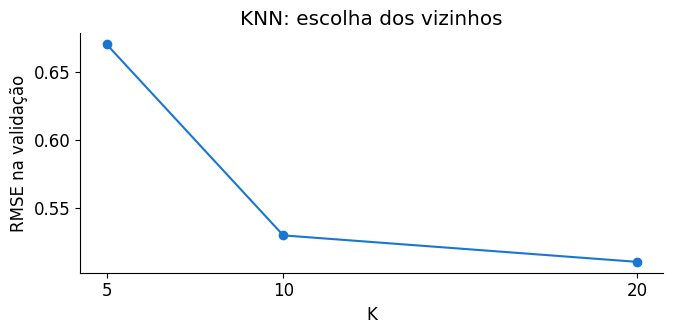

In [9]:
opcoes_knn=[]
for k in [5,10,20]:
    candidato=ajustar_knn(treino,k)
    estimadas=prever_matriz(validacao,candidato['notas'])
    opcoes_knn.append({'K':k,'RMSE':np.sqrt(mean_squared_error(validacao.nota,estimadas)),
                       'MAE':mean_absolute_error(validacao.nota,estimadas)})
validacao_knn=pd.DataFrame(opcoes_knn)
k_escolhido=int(validacao_knn.loc[validacao_knn.RMSE.idxmin(),'K'])
display(validacao_knn.round(3))
print('K escolhido na validação:',k_escolhido)
ax=validacao_knn.plot(x='K',y='RMSE',marker='o',color='#1976D2',legend=False,figsize=(7,3.5))
ax.set(title='KNN: escolha dos vizinhos',ylabel='RMSE na validação',xticks=[5,10,20])
plt.tight_layout();plt.show()

### O que significa ser vizinho aqui?

O gráfico escolhe o K pelo menor erro de validação. A tabela seguinte mostra os usuários mais próximos do primeiro perfil da matriz. A distância mede semelhança entre padrões de notas disponíveis; ela não indica amizade nem proximidade social.

In [10]:
exemplo_usuario=treino.usuario_id.iloc[0]
modelo_knn_treino=ajustar_knn(treino,k_escolhido)
linha=modelo_knn_treino['usuarios'].get_loc(exemplo_usuario)
display(pd.DataFrame({'Vizinho':modelo_knn_treino['usuarios'][modelo_knn_treino['vizinhos'][linha,:5]],
                      'Distância':modelo_knn_treino['distancias'][linha,:5]}).round(3))
display(treino[treino.usuario_id==exemplo_usuario].merge(filmes,on='filme_id')[['titulo','categoria','nota']].head(8))

,Vizinho,Distância
0,U1959,0.35
1,U0317,0.41
2,U0534,0.43
3,U0119,0.44
4,U0352,0.47


,titulo,categoria,nota
0,Matrix,Ficção científica,4.50
1,E.T.: O Extraterrestre,Ficção científica,4.50
2,Toy Story,Animação,2.00
3,Gente Grande,Comédia,4.50
4,Velocidade Máxima,Ação,5.00
5,Piratas do Caribe: A Maldição do Pérola Negra,Aventura,4.50
6,Diário de uma Paixão,Romance,1.50
7,Mad Max: Estrada da Fúria,Ação,4.50


## 6. SVD: resumir a matriz em fatores

O SVD procura padrões compartilhados que permitam representar a matriz com menos dimensões. Os fatores não chegam com nomes como “ação” ou “romance”. Para lidar com notas ausentes, começamos por uma referência aprendida no treino, aplicamos SVD truncada e atualizamos apenas posições sem nota. As notas observadas são preservadas durante esse preenchimento.

In [11]:
def ajustar_svd(dados, fatores, rodadas=40):
    matriz = dados.pivot(index='usuario_id', columns='filme_id', values='nota').reindex(columns=filmes.filme_id)
    usuarios = matriz.index
    valores = matriz.to_numpy()
    observadas = np.isfinite(valores)
    media = dados.nota.mean()
    efeito_usuario = np.nansum(valores-media, axis=1) / (observadas.sum(axis=1)+5)
    efeito_filme = np.nansum(valores-media-efeito_usuario[:,None], axis=0) / (observadas.sum(axis=0)+10)
    referencia = media + efeito_usuario[:,None] + efeito_filme
    residuos = np.where(observadas, valores-referencia, 0)
    preenchida = residuos.copy()
    with threadpool_limits(limits=2):
        for _ in range(rodadas):
            u, importancia, vt = np.linalg.svd(preenchida, full_matrices=False)
            aproximacao = (u[:, :fatores] * importancia[:fatores]) @ vt[:fatores]
            preenchida = np.where(observadas, residuos, aproximacao)
    return pd.DataFrame(np.clip(referencia+aproximacao,1,5), index=usuarios, columns=matriz.columns)


def prever(dados, matriz):
    linhas = matriz.index.get_indexer(dados.usuario_id)
    colunas = matriz.columns.get_indexer(dados.filme_id)
    if (linhas < 0).any() or (colunas < 0).any():
        raise ValueError('Usuário ou filme sem histórico no ajuste.')
    return matriz.to_numpy()[linhas, colunas]

## 7. Escolher a quantidade de fatores

Poucos fatores podem perder diferenças importantes. Muitos fatores podem reproduzir particularidades do treino. Testamos algumas alternativas e escolhemos a que obteve menor RMSE na validação. O gráfico deve ser lido pelo ponto mais baixo, não pela ideia de que mais fatores sempre melhoram.

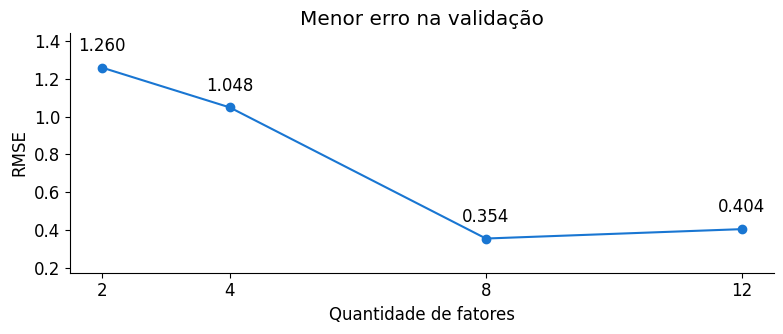

Escolha: 8 fatores. Acrescentar fatores além desse ponto não melhorou a validação.


In [12]:
resultados_validacao = []
for quantidade in [2, 4, 8, 12]:
    candidato = ajustar_svd(treino, fatores=quantidade)
    erro = np.sqrt(mean_squared_error(validacao.nota, prever(validacao, candidato)))
    resultados_validacao.append({'Fatores': quantidade, 'RMSE': erro})
comparacao_validacao = pd.DataFrame(resultados_validacao)
fatores_escolhidos = int(comparacao_validacao.loc[comparacao_validacao.RMSE.idxmin(), 'Fatores'])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(comparacao_validacao.Fatores, comparacao_validacao.RMSE, 'o-', color='#1976D2')
for linha in comparacao_validacao.itertuples():
    ax.annotate(f'{linha.RMSE:.3f}', (linha.Fatores, linha.RMSE), xytext=(0, 12), textcoords='offset points', ha='center')
ax.set(title='Menor erro na validação', xlabel='Quantidade de fatores', ylabel='RMSE', xticks=[2,4,8,12])
ax.margins(y=.2)
plt.tight_layout()
plt.show()
print(f'Escolha: {fatores_escolhidos} fatores. Acrescentar fatores além desse ponto não melhorou a validação.')

## 8. Ponte com a aula 15: centros, grupos e preferências

O centro do K-means resume as características médias de um grupo. Para mostrar a ligação com recomendação, vamos representar cada usuário pelas **notas médias que deu às categorias**, usando apenas o treino. Aqui as colunas já descrevem preferências. Frequência de postagem ou número de curtidas, sozinhos, não informariam quais filmes a pessoa gosta.

Escolhemos a quantidade de grupos pela silhueta no treino. Depois usamos as médias de cada filme dentro do grupo como um recomendador simples. Isso permite comparar uma recomendação igual para membros do mesmo grupo com a personalização do KNN e do SVD. Não restringiremos os candidatos aos grupos: assim todos os métodos enfrentam o mesmo teste.

,Grupos,Silhueta
0,2,0.14
1,3,0.13
2,4,0.14
3,5,0.16
4,6,0.16
5,7,0.16
6,8,0.17


Quantidade escolhida entre as alternativas examinadas: 8
A silhueta mede separação interna. A qualidade da recomendação será medida depois.


categoria,Animação,Aventura,Ação,Comédia,Drama,Ficção científica,Romance,Terror
1,3.48,3.27,3.38,4.54,3.68,1.84,1.86,3.62
2,2.59,2.52,2.57,4.55,2.88,4.48,3.04,2.95
3,3.38,4.57,3.35,1.89,3.67,3.29,1.85,3.61
4,4.17,1.90,3.82,1.88,3.90,4.00,1.87,4.03
5,3.09,2.87,3.05,1.88,2.86,4.49,4.52,2.86
6,4.63,2.90,2.96,3.02,2.97,1.81,4.54,2.79
7,4.18,4.11,3.89,4.02,1.75,3.93,1.85,1.86
8,1.93,3.56,3.57,3.46,3.23,1.80,4.52,3.49


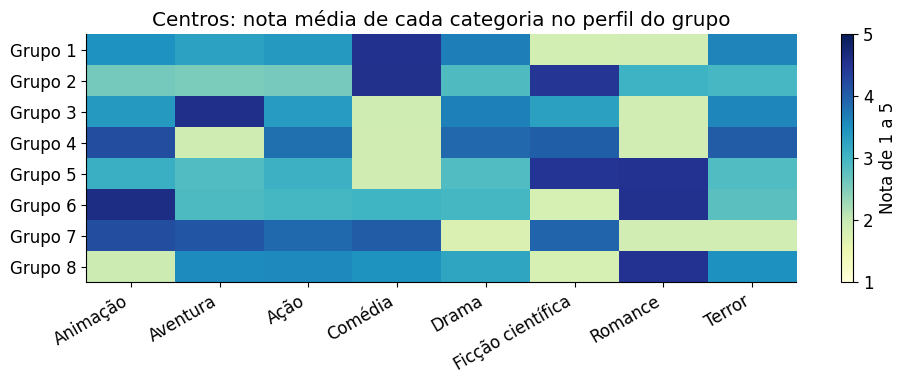

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def perfis_categorias(dados):
    return dados.merge(filmes,on='filme_id').pivot_table(
        index='usuario_id',columns='categoria',values='nota',aggfunc='mean')

perfis=perfis_categorias(treino)
medias_categorias=perfis.mean()
perfis_completos=perfis.fillna(medias_categorias)
# Todas as colunas usam a mesma escala de notas. Mantemos essa unidade para ler os centros.
opcoes_grupos=[]
for k in range(2,9):
    km=KMeans(n_clusters=k,n_init=10,random_state=42).fit(perfis_completos)
    opcoes_grupos.append({'Grupos':k,'Silhueta':silhouette_score(
        perfis_completos,km.labels_,sample_size=1000,random_state=42)})
comparacao_grupos=pd.DataFrame(opcoes_grupos)
k_grupos=int(comparacao_grupos.loc[comparacao_grupos.Silhueta.idxmax(),'Grupos'])
display(comparacao_grupos.round(3))
print('Quantidade escolhida entre as alternativas examinadas:',k_grupos)
print('A silhueta mede separação interna. A qualidade da recomendação será medida depois.')

def ajustar_grupos(dados,k):
    quadro=perfis_categorias(dados)
    preenchido=quadro.fillna(quadro.mean())
    km=KMeans(n_clusters=k,n_init=10,random_state=42).fit(preenchido)
    rotulos=pd.Series(km.labels_+1,index=quadro.index,name='Grupo')
    medias=dados.join(rotulos,on='usuario_id').groupby(['Grupo','filme_id']).nota.mean().unstack()
    medias=medias.reindex(columns=filmes.filme_id).fillna(dados.groupby('filme_id').nota.mean())
    notas=pd.DataFrame(medias.loc[rotulos].to_numpy(),index=quadro.index,columns=medias.columns)
    centros=pd.DataFrame(km.cluster_centers_,columns=quadro.columns,index=range(1,k+1))
    return {'notas':notas,'grupos':rotulos,'centros':centros,'modelo':km}

grupos_treino=ajustar_grupos(treino,k_grupos)
display(grupos_treino['centros'].round(2))
fig,ax=plt.subplots(figsize=(10,4))
im=ax.imshow(grupos_treino['centros'],vmin=1,vmax=5,cmap='YlGnBu',aspect='auto')
ax.set_xticks(range(len(perfis.columns)),perfis.columns,rotation=30,ha='right')
ax.set_yticks(range(k_grupos),[f'Grupo {i}' for i in range(1,k_grupos+1)])
ax.set_title('Centros: nota média de cada categoria no perfil do grupo')
fig.colorbar(im,ax=ax,label='Nota de 1 a 5');plt.tight_layout();plt.show()

Leia cada linha do mapa como o perfil médio de um grupo. Uma cor mais escura indica maior preferência média naquela categoria. O centro pode reunir valores que nenhuma pessoa possui exatamente. Pessoas do mesmo grupo ainda têm diferenças individuais, que os outros modelos podem aproveitar.

Em um catálogo grande, os grupos também poderiam ajudar a selecionar candidatos antes da ordenação. Essa filtragem precisaria de avaliação própria: excluir um item cedo demais impede que KNN ou SVD o recupere depois.

## 9. Como os modelos serão avaliados

**MAE** indica a diferença absoluta média entre nota prevista e nota real. **RMSE** também expressa erro na escala de 1 a 5 e aumenta mais quando ocorrem erros grandes. Menor é melhor em ambas. **Precisão@5** responde outra pergunta: dentre os cinco filmes colocados no topo de um painel de teste, quantos receberam nota 4 ou 5? Maior é melhor.

O painel contém somente os filmes reservados para teste de cada usuário. Filmes nunca avaliados não viram “erro” nem “rejeição”. Por isso, a precisão não afirma que conhecemos a qualidade da lista em todo o catálogo. Compararemos com a média de cada filme, uma referência que não personaliza a previsão.

In [14]:
def avaliar(dados, previsoes):
    painel = dados.assign(nota_estimada=previsoes)
    contagens = painel.groupby('usuario_id').size()
    if contagens.min() < 5:
        raise ValueError('Cada usuário precisa de pelo menos cinco candidatos para esta avaliação.')
    lista = painel.sort_values(['usuario_id','nota_estimada','filme_id'], ascending=[True,False,True]).groupby('usuario_id').head(5)
    precisao = lista.nota.ge(4).mean()
    teto = painel.nota.ge(4).groupby(painel.usuario_id).sum().clip(upper=5).mean()/5
    rmse = np.sqrt(mean_squared_error(dados.nota, previsoes))
    return rmse, precisao, teto, lista

In [15]:
# A precisão possível pode ser menor que 100% quando um painel tem menos de cinco notas 4 ou 5.
print('Painéis de teste:',teste.usuario_id.nunique())
print('Candidatos por usuário, mínimo e máximo:',teste.groupby('usuario_id').size().min(),teste.groupby('usuario_id').size().max())

Painéis de teste: 2000
Candidatos por usuário, mínimo e máximo: 10 12


## 10. Teste final: referência, grupos, KNN e SVD

Agora reunimos treino e validação, ajustamos KNN e SVD com as configurações escolhidas e abrimos o teste uma única vez. Todos os métodos enfrentam as mesmas avaliações. A tabela informa tanto o erro das notas quanto a qualidade do topo da lista.

,RMSE,MAE,Precisão@5 (%)
Método,,,
Média dos filmes,1.37,1.35,50.15
K-means: média do grupo,1.06,0.85,75.84
KNN,0.35,0.26,95.59
SVD,0.29,0.21,95.65


Limite possível de Precisão@5 neste painel: 95.65%.


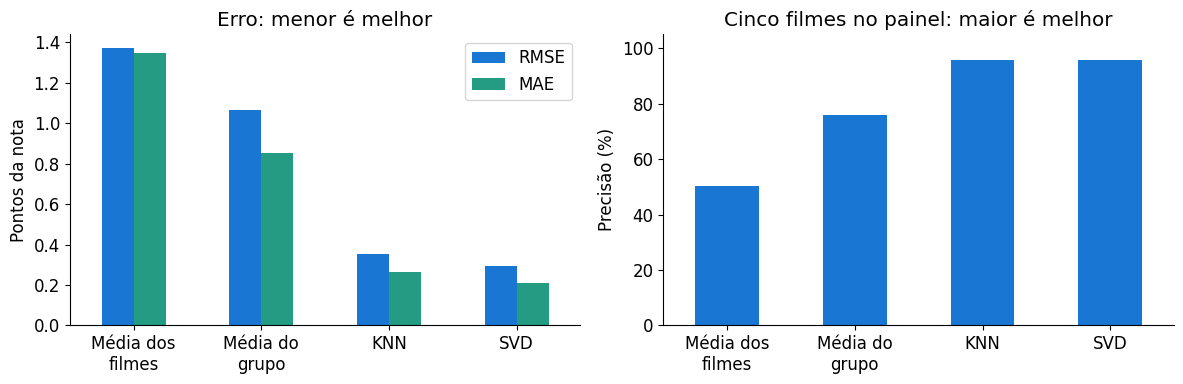

In [16]:
historico=pd.concat([treino,validacao],ignore_index=True)
modelo_knn=ajustar_knn(historico,k_escolhido)
modelo_svd=ajustar_svd(historico,fatores=fatores_escolhidos)
modelo_grupos=ajustar_grupos(historico,k_grupos)
medias_filmes=historico.groupby('filme_id').nota.mean()
previsoes={
    'Média dos filmes':teste.filme_id.map(medias_filmes).to_numpy(),
    'K-means: média do grupo':prever_matriz(teste,modelo_grupos['notas']),
    'KNN':prever_matriz(teste,modelo_knn['notas']),
    'SVD':prever_matriz(teste,modelo_svd)}
linhas=[];listas={}
for nome,preds in previsoes.items():
    rmse,precisao,teto,lista=avaliar(teste,preds)
    listas[nome]=lista
    linhas.append({'Método':nome,'RMSE':rmse,'MAE':mean_absolute_error(teste.nota,preds),'Precisão@5 (%)':100*precisao})
resultado=pd.DataFrame(linhas).set_index('Método')
display(resultado.round(3))
print(f'Limite possível de Precisão@5 neste painel: {100*teto:.2f}%.')
fig,ax=plt.subplots(1,2,figsize=(12,4))
resultado.rename(index={'K-means: média do grupo':'Média do\ngrupo','Média dos filmes':'Média dos\nfilmes'})[['RMSE','MAE']].plot.bar(ax=ax[0],rot=0,color=['#1976D2','#249C84'])
ax[0].set(title='Erro: menor é melhor',ylabel='Pontos da nota',xlabel='')
resultado.rename(index={'K-means: média do grupo':'Média do\ngrupo','Média dos filmes':'Média dos\nfilmes'})[['Precisão@5 (%)']].plot.bar(ax=ax[1],rot=0,color='#1976D2',legend=False)
ax[1].set(title='Cinco filmes no painel: maior é melhor',ylabel='Precisão (%)',xlabel='',ylim=(0,105))
plt.tight_layout();plt.show()

## 11. Interpretar o resultado

Leia primeiro o RMSE: qual método errou menos as notas? Depois compare a precisão das listas. Observe também o limite possível do painel. Se uma pessoa gostou de apenas três candidatos, nenhuma lista de cinco terá cinco acertos para ela. O código abaixo produz uma conclusão a partir do teste, sem chamar RMSE ou precisão de “acurácia geral”.

In [17]:
referencia=resultado.loc['Média dos filmes']
for nome in ['KNN','SVD']:
    atual=resultado.loc[nome]
    ganho_erro=100*(referencia.RMSE-atual.RMSE)/referencia.RMSE
    ganho_lista=atual['Precisão@5 (%)']-referencia['Precisão@5 (%)']
    print(f'{nome}: RMSE {atual.RMSE:.3f}, {ganho_erro:.1f}% menos erro que a média dos filmes; '
          f'Precisão@5 {atual["Precisão@5 (%)"]:.2f}%, diferença de {ganho_lista:+.2f} pontos percentuais.')
vencedor=resultado.RMSE.idxmin()
print('Menor erro nas notas reservadas:',vencedor)
print('A conclusão descreve esta base simulada e este painel, não usuários reais.')

KNN: RMSE 0.352, 74.3% menos erro que a média dos filmes; Precisão@5 95.59%, diferença de +45.44 pontos percentuais.
SVD: RMSE 0.295, 78.5% menos erro que a média dos filmes; Precisão@5 95.65%, diferença de +45.50 pontos percentuais.
Menor erro nas notas reservadas: SVD
A conclusão descreve esta base simulada e este painel, não usuários reais.


## 12. Comparação direta entre KNN e SVD

A comparação com a média dos filmes mostra se personalizar ajudou. Agora vamos comparar **SVD diretamente com KNN**. Para RMSE e MAE, uma redução é favorável. Para Precisão@5, observamos a diferença em pontos percentuais. Resultados muito próximos na lista podem acompanhar diferenças maiores no erro das notas: ordenar bem e prever a nota exata são objetivos diferentes.

In [18]:
direta=pd.DataFrame({
    'KNN':resultado.loc['KNN'],
    'SVD':resultado.loc['SVD']})
direta['Diferença SVD − KNN']=direta.SVD-direta.KNN
display(direta.round(4))
for metrica in ['RMSE','MAE']:
    a,b=resultado.loc['KNN',metrica],resultado.loc['SVD',metrica]
    print(f'{metrica}: KNN {a:.4f}; SVD {b:.4f}; redução relativa do SVD: {100*(a-b)/a:.2f}%.')
delta=resultado.loc['SVD','Precisão@5 (%)']-resultado.loc['KNN','Precisão@5 (%)']
print(f'Precisão@5: diferença de {delta:+.3f} ponto percentual para SVD.')
print('Uma diferença pequena no topo da lista deve ser descrita como pequena, mesmo quando o RMSE melhora.')

,KNN,SVD,Diferença SVD − KNN
RMSE,0.35,0.29,-0.06
MAE,0.26,0.21,-0.05
Precisão@5 (%),95.59,95.65,0.06


RMSE: KNN 0.3516; SVD 0.2947; redução relativa do SVD: 16.18%.
MAE: KNN 0.2628; SVD 0.2119; redução relativa do SVD: 19.37%.
Precisão@5: diferença de +0.060 ponto percentual para SVD.
Uma diferença pequena no topo da lista deve ser descrita como pequena, mesmo quando o RMSE melhora.


## 13. Avaliar a lista: recuperar itens e colocá-los no topo

**Precisão@5** conta quantos dos cinco recomendados são relevantes. **Revocação@5** conta quantos dos filmes relevantes disponíveis no painel foram recuperados. Uma pessoa com oito relevantes pode ter cinco acertos na lista e ainda ter revocação inferior a 100%.

**NDCG@5** considera também a posição: colocar um relevante no começo vale mais que colocá-lo no fim. Dividimos o resultado pela melhor ordem possível para aquele painel. O valor vai de zero a um; maior é melhor. Usaremos relevância binária: nota a partir de 4. Usuários sem nenhum relevante não entram nas médias de revocação e NDCG. Empates de previsão são resolvidos pelo ID do filme, igual para todos os métodos.

,RMSE,MAE,Precisão@5,Revocação@5,NDCG@5
Método,,,,,
Média dos filmes,1.37,1.35,0.50,0.42,0.51
K-means: média do grupo,1.06,0.85,0.76,0.65,0.83
KNN,0.35,0.26,0.96,0.84,1.00
SVD,0.29,0.21,0.96,0.84,1.00


Usuários sem relevantes no painel: 0
Precisão e revocação estão nesta tabela na escala de 0 a 1.


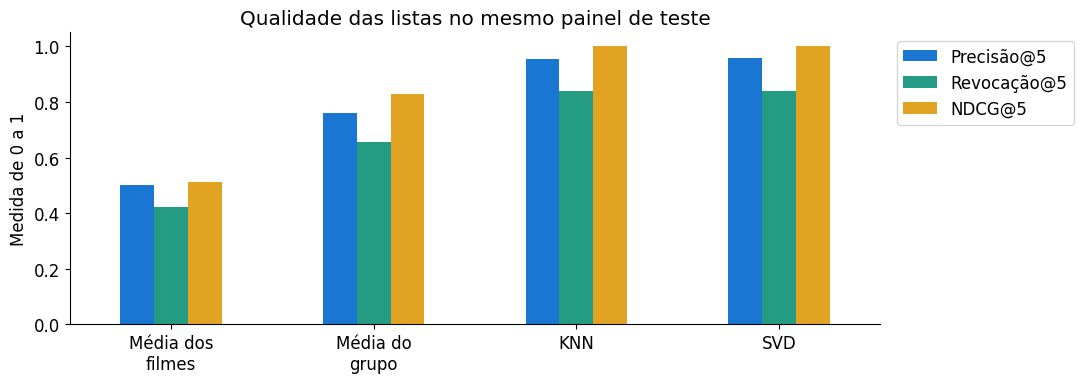

In [19]:
def avaliar_por_usuario(dados,preds,nome):
    painel=dados.assign(estimada=preds).sort_values(
        ['usuario_id','estimada','filme_id'],ascending=[True,False,True])
    saida=[]
    for usuario,g in painel.groupby('usuario_id',sort=True):
        rel=(g.nota.to_numpy()>=4).astype(int)
        topo=rel[:5];total=int(rel.sum());desconto=1/np.log2(np.arange(2,len(topo)+2))
        ideal=desconto[:min(total,5)].sum()
        erros=g.nota.to_numpy()-g.estimada.to_numpy()
        saida.append({'usuario_id':usuario,'Método':nome,'N':len(g),
            'Soma quadrados':np.sum(erros**2),'MAE':np.abs(erros).mean(),
            'RMSE':np.sqrt(np.mean(erros**2)),'Precisão@5':topo.sum()/5,
            'Revocação@5':topo.sum()/total if total else np.nan,
            'NDCG@5':np.sum(topo*desconto)/ideal if ideal else np.nan,
            'Relevantes':total,'Acertos no topo':topo.sum()})
    return pd.DataFrame(saida)

por_usuario=pd.concat([avaliar_por_usuario(teste,p,nome) for nome,p in previsoes.items()],ignore_index=True)
qualidade=por_usuario.groupby('Método')[['Precisão@5','Revocação@5','NDCG@5']].mean()
comparacao_completa=resultado[['RMSE','MAE']].join(qualidade)
display(comparacao_completa.round(4))
print('Usuários sem relevantes no painel:',por_usuario[por_usuario['Método']=='SVD'].Relevantes.eq(0).sum())
print('Precisão e revocação estão nesta tabela na escala de 0 a 1.')
ax=qualidade.reindex(resultado.index).rename(index={'K-means: média do grupo':'Média do\ngrupo','Média dos filmes':'Média dos\nfilmes'}).plot.bar(figsize=(11,4),rot=0,ylim=(0,1.05),color=['#1976D2','#249C84','#E3A322'])
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1))
ax.set(ylabel='Medida de 0 a 1',xlabel='',title='Qualidade das listas no mesmo painel de teste')
plt.tight_layout();plt.show()

## 14. O ganho aparece para todos os usuários?

O RMSE global dá mais peso a quem possui mais avaliações. Para examinar pessoas, calculamos o MAE de cada usuário e comparamos KNN com SVD para o mesmo ID. O histograma mostra a diferença **MAE do SVD menos MAE do KNN**: valores negativos favorecem SVD, positivos favorecem KNN. A média geral pode esconder usuários que pioraram.

SVD com menor MAE: 73.6% dos usuários.
KNN com menor MAE: 26.5% dos usuários.
Empate numérico: 0.0% dos usuários.
Percentis do MAE por usuário:


Método,KNN,SVD
0.10,0.17,0.14
0.50,0.25,0.20
0.90,0.38,0.28
0.95,0.43,0.31


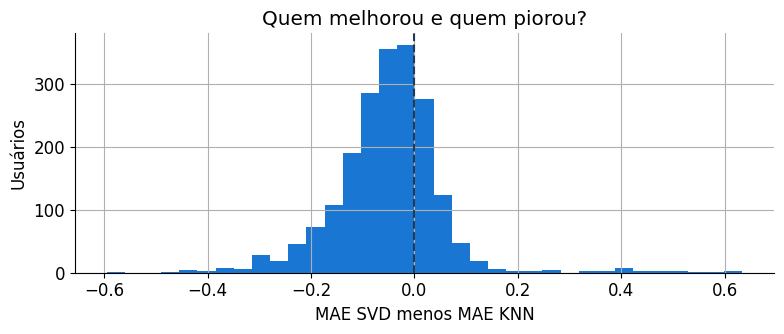

In [20]:
erros_usuarios=por_usuario.pivot(index='usuario_id',columns='Método',values='MAE')
dif_usuarios=erros_usuarios.SVD-erros_usuarios.KNN
print(f'SVD com menor MAE: {(dif_usuarios < -1e-8).mean():.1%} dos usuários.')
print(f'KNN com menor MAE: {(dif_usuarios > 1e-8).mean():.1%} dos usuários.')
print(f'Empate numérico: {(dif_usuarios.abs() <= 1e-8).mean():.1%} dos usuários.')
print('Percentis do MAE por usuário:')
display(erros_usuarios[['KNN','SVD']].quantile([.1,.5,.9,.95]).round(3))
ax=dif_usuarios.hist(bins=35,figsize=(8,3.5),color='#1976D2')
ax.axvline(0,color='#253A52',linestyle='--')
ax.set(xlabel='MAE SVD menos MAE KNN',ylabel='Usuários',title='Quem melhorou e quem piorou?')
plt.tight_layout();plt.show()

## 15. Quanto uma pequena diferença pode variar?

Vamos reamostrar usuários completos do teste, mantendo as previsões já prontas. Em cada repetição, entram os mesmos usuários sorteados para KNN e SVD. O intervalo central de 95% dessas diferenças mostra a variação da comparação ao mudar a composição dos usuários. Se incluir zero, a vantagem nessa métrica não está bem definida por esta amostra. Esse cálculo não retreina modelos e não mede toda a incerteza de uso em outra população.

In [21]:
a=por_usuario[por_usuario['Método']=='KNN'].set_index('usuario_id').sort_index()
b=por_usuario[por_usuario['Método']=='SVD'].set_index('usuario_id').reindex(a.index)
rng=np.random.default_rng(42);diferencas=[]
for _ in range(500):
    ix=rng.integers(0,len(a),len(a))
    aa,bb=a.iloc[ix],b.iloc[ix]
    dr=np.sqrt(bb['Soma quadrados'].sum()/bb.N.sum())-np.sqrt(aa['Soma quadrados'].sum()/aa.N.sum())
    dp=100*(bb['Precisão@5'].mean()-aa['Precisão@5'].mean())
    diferencas.append([dr,dp])
intervalos=pd.DataFrame(diferencas,columns=['RMSE: SVD − KNN','Precisão@5: diferença em p.p.']).quantile([.025,.5,.975]).T
intervalos.columns=['Limite inferior','Mediana','Limite superior']
display(intervalos.round(4))
for metrica,linha in intervalos.iterrows():
    leitura='inclui zero: diferença sem direção clara nesta reamostragem' if linha.iloc[0]<=0<=linha.iloc[2] else 'não inclui zero: diferença consistente nesta reamostragem'
    print(metrica,'—',leitura)

,Limite inferior,Mediana,Limite superior
RMSE: SVD − KNN,-0.07,-0.06,-0.05
Precisão@5: diferença em p.p.,0.01,0.05,0.14


RMSE: SVD − KNN — não inclui zero: diferença consistente nesta reamostragem
Precisão@5: diferença em p.p. — não inclui zero: diferença consistente nesta reamostragem


## 16. Cobertura e concentração das recomendações

Duas listas podem acertar bastante e repetir quase sempre os mesmos títulos. A cobertura mostra quantos filmes diferentes chegaram ao topo de pelo menos uma lista. Neste exercício, ela é medida **somente nos painéis de teste**. Cobertura alta não garante relevância; ajuda a perceber o quanto o catálogo foi utilizado. Vamos observar também se uma única categoria concentra a maior parte das sugestões.

In [22]:
resumos=[]
for nome,preds in previsoes.items():
    painel=teste.assign(estimada=preds).sort_values(['usuario_id','estimada','filme_id'],ascending=[True,False,True])
    topo=painel.groupby('usuario_id',sort=False).head(5).merge(filmes,on='filme_id')
    participacao=topo.categoria.value_counts(normalize=True)
    resumos.append({'Método':nome,'Filmes diferentes':topo.filme_id.nunique(),
        'Cobertura do catálogo (%)':100*topo.filme_id.nunique()/len(filmes),
        'Categoria mais presente':participacao.index[0],
        'Participação dessa categoria (%)':100*participacao.iloc[0]})
display(pd.DataFrame(resumos).set_index('Método').round(2))
print('Esta base tem exposição sorteada e catálogo pequeno. Dados reais podem ter concentração e popularidade muito diferentes.')

,Filmes diferentes,Cobertura do catálogo (%),Categoria mais presente,Participação dessa categoria (%)
Método,,,,
Média dos filmes,35,72.92,Animação,23.44
K-means: média do grupo,48,100.00,Comédia,14.82
KNN,48,100.00,Animação,14.10
SVD,48,100.00,Animação,13.90


Esta base tem exposição sorteada e catálogo pequeno. Dados reais podem ter concentração e popularidade muito diferentes.


## 17. Onde ainda há erro?

Uma média boa pode esconder falhas em certos filmes ou categorias. Vamos comparar o erro absoluto por categoria e observar as notas reais diante das estimadas. A categoria entra apenas nesta análise posterior, não como entrada dos modelos.

,MAE KNN,MAE SVD
categoria,,
Aventura,0.26,0.20
Ação,0.25,0.20
Animação,0.25,0.21
Comédia,0.27,0.21
Drama,0.27,0.21
Romance,0.27,0.22
Ficção científica,0.26,0.22
Terror,0.27,0.22


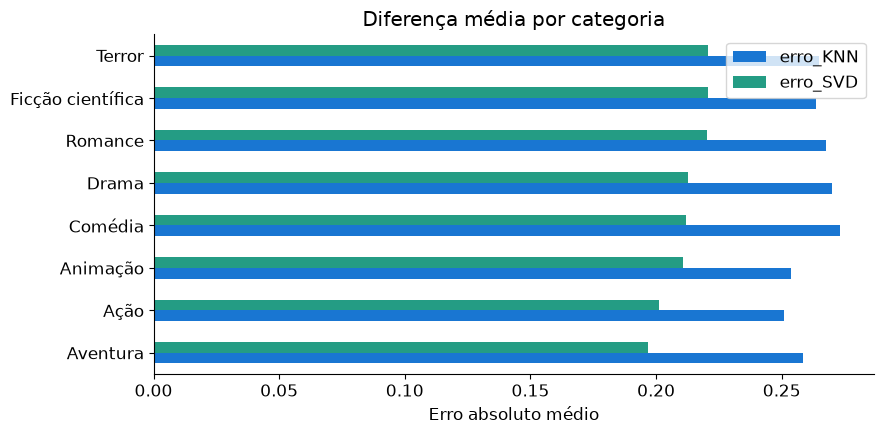

In [ ]:
detalhe=teste.merge(filmes,on='filme_id').copy()
detalhe['erro_KNN']=np.abs(detalhe.nota.to_numpy()-previsoes['KNN'])
detalhe['erro_SVD']=np.abs(detalhe.nota.to_numpy()-previsoes['SVD'])
por_categoria=detalhe.groupby('categoria')[['erro_KNN','erro_SVD']].mean().sort_values('erro_SVD')
display(por_categoria.rename(columns={'erro_KNN':'MAE KNN','erro_SVD':'MAE SVD'}).round(3))
ax=por_categoria.plot.barh(figsize=(9,4.5),color=['#1976D2','#249C84'])
ax.set(title='Diferença média por categoria',xlabel='Erro absoluto médio',ylabel='')
plt.tight_layout();plt.show()

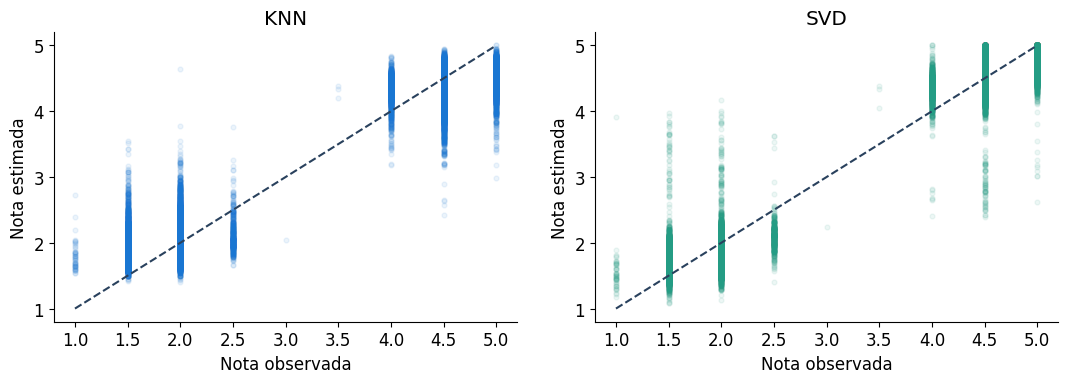

Pontos próximos da diagonal indicam estimativas próximas da nota observada.


In [23]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for eixo,nome,cor in [(ax[0],'KNN','#1976D2'),(ax[1],'SVD','#249C84')]:
    eixo.scatter(teste.nota,previsoes[nome],alpha=.08,s=12,color=cor)
    eixo.plot([1,5],[1,5],color='#29415D',linestyle='--')
    eixo.set(title=nome,xlabel='Nota observada',ylabel='Nota estimada',xlim=(.8,5.2),ylim=(.8,5.2))
plt.tight_layout();plt.show()
print('Pontos próximos da diagonal indicam estimativas próximas da nota observada.')

## 18. Conferir um usuário sem escolher o melhor caso

Usaremos o primeiro usuário do teste, sem procurar uma pessoa cuja lista ficou mais bonita. A nota observada só é mostrada agora, depois da ordenação. Compare o que KNN e SVD colocaram nas primeiras posições.

In [24]:
usuario_exemplo=teste.usuario_id.iloc[0]
for nome in ['KNN','SVD']:
    lista=listas[nome]
    amostra=lista[lista.usuario_id==usuario_exemplo].merge(filmes,on='filme_id').copy()
    amostra['Relevante?']=np.where(amostra.nota>=4,'Sim','Não')
    print(nome,'— usuário',usuario_exemplo)
    display(amostra[['titulo','categoria','nota_estimada','nota','Relevante?']].rename(columns={
        'titulo':'Filme','categoria':'Categoria','nota_estimada':'Nota estimada','nota':'Nota observada'}).reset_index(drop=True).round(2))

KNN — usuário U0001


,Filme,Categoria,Nota estimada,Nota observada,Relevante?
0,Duro de Matar,Ação,4.72,5.00,Sim
1,Harry Potter e a Pedra Filosofal,Aventura,4.46,4.50,Sim
2,As Branquelas,Comédia,4.26,4.50,Sim
3,Debi & Lóide: Dois Idiotas em Apuros,Comédia,4.15,5.00,Sim
4,Jumanji,Aventura,3.90,4.00,Sim


SVD — usuário U0001


,Filme,Categoria,Nota estimada,Nota observada,Relevante?
0,As Branquelas,Comédia,4.64,4.50,Sim
1,Duro de Matar,Ação,4.63,5.00,Sim
2,Debi & Lóide: Dois Idiotas em Apuros,Comédia,4.58,5.00,Sim
3,Harry Potter e a Pedra Filosofal,Aventura,4.26,4.50,Sim
4,Jumanji,Aventura,4.11,4.00,Sim


## 19. Recomendar outros filmes por input

Digite o ID de uma pessoa que está na base, como `U0001`. O modelo usa as avaliações disponíveis até a 28ª posição. Os filmes desse histórico são retirados da lista. Podemos pedir KNN, SVD ou os dois e, se desejarmos, filtrar uma categoria. Uma nota estimada é uma previsão na escala de 1 a 5, não a probabilidade de gostar.

In [25]:
def recomendar(usuario,metodo='SVD',categoria=None,quantidade=5):
    if usuario not in modelo_svd.index:raise ValueError('Usuário inexistente. Confira o ID.')
    fontes={'KNN':modelo_knn['notas'],'SVD':modelo_svd}
    if metodo not in fontes:raise ValueError('Escolha KNN ou SVD.')
    conhecidos=set(historico.loc[historico.usuario_id==usuario,'filme_id'])
    candidatos=filmes[~filmes.filme_id.isin(conhecidos)].copy()
    if categoria:candidatos=candidatos[candidatos.categoria==categoria]
    candidatos['nota_estimada']=fontes[metodo].loc[usuario,candidatos.filme_id].to_numpy()
    return candidatos.sort_values(['nota_estimada','filme_id'],ascending=[False,True]).head(quantidade)[
        ['titulo','categoria','nota_estimada']].rename(columns={'titulo':'Filme','categoria':'Categoria','nota_estimada':'Nota estimada'}).reset_index(drop=True).round(2)

print('Categorias:',', '.join(sorted(filmes.categoria.unique())))
display(recomendar('U0001','KNN'))
display(recomendar('U0001','SVD'))

Categorias: Animação, Aventura, Ação, Comédia, Drama, Ficção científica, Romance, Terror


,Filme,Categoria,Nota estimada
0,Duro de Matar,Ação,4.72
1,Missão: Impossível,Ação,4.57
2,Harry Potter e a Pedra Filosofal,Aventura,4.46
3,Blade Runner: O Caçador de Androides,Ficção científica,4.31
4,As Branquelas,Comédia,4.26


,Filme,Categoria,Nota estimada
0,As Branquelas,Comédia,4.64
1,"Se Beber, Não Case!",Comédia,4.64
2,Duro de Matar,Ação,4.63
3,Debi & Lóide: Dois Idiotas em Apuros,Comédia,4.58
4,Missão: Impossível,Ação,4.54


### Comparar as duas listas de uma pessoa

A tabela a seguir junta as recomendações que aparecem no topo de pelo menos um dos dois modelos. A posição vazia indica que o filme não ficou entre os cinco daquele método. Uma nota estimada maior não significa automaticamente que aquele filme seja um acerto: para itens ainda não avaliados, a opinião real permanece desconhecida.

In [26]:
def comparar_listas(usuario,categoria=None):
    tabelas=[]
    for nome in ['KNN','SVD']:
        lista=recomendar(usuario,nome,categoria).copy()
        lista['Posição '+nome]=np.arange(1,len(lista)+1)
        lista=lista.rename(columns={'Nota estimada':'Nota '+nome})
        tabelas.append(lista)
    quadro=tabelas[0].merge(tabelas[1],on=['Filme','Categoria'],how='outer')
    comuns=quadro['Posição KNN'].notna() & quadro['Posição SVD'].notna()
    print('Grupo do usuário:',int(modelo_grupos['grupos'].loc[usuario]))
    print('Filmes presentes nas duas listas:',int(comuns.sum()),'de até cinco.')
    display(quadro.sort_values(['Posição SVD','Posição KNN']).round(2))

comparar_listas('U0001')

Grupo do usuário: 7
Filmes presentes nas duas listas: 3 de até cinco.


,Filme,Categoria,Nota KNN,Posição KNN,Nota SVD,Posição SVD
0,As Branquelas,Comédia,4.26,5.00,4.64,1.00
6,"Se Beber, Não Case!",Comédia,NaN,NaN,4.64,2.00
3,Duro de Matar,Ação,4.72,1.00,4.63,3.00
2,Debi & Lóide: Dois Idiotas em Apuros,Comédia,NaN,NaN,4.58,4.00
5,Missão: Impossível,Ação,4.57,2.00,4.54,5.00
4,Harry Potter e a Pedra Filosofal,Aventura,4.46,3.00,NaN,NaN
1,Blade Runner: O Caçador de Androides,Ficção científica,4.31,4.00,NaN,NaN


In [27]:
while True:
    usuario=input('ID do usuário (ex.: U0001): ').strip().upper()
    if usuario.isdigit():usuario='U'+usuario.zfill(4)
    if usuario in modelo_svd.index:break
    print('Esse ID não está na base.')
while True:
    categoria=input('Categoria ou Enter para todas: ').strip()
    if not categoria or categoria in set(filmes.categoria):break
    print('Use uma das categorias mostradas acima.')
for nome in ['KNN','SVD']:
    print(nome,'para',usuario)
    display(recomendar(usuario,nome,categoria or None))
comparar_listas(usuario,categoria or None)

ID do usuário (ex.: U0001): U0003
Categoria ou Enter para todas: Comédia
KNN para U0003


,Filme,Categoria,Nota estimada
0,O Mentiroso,Comédia,4.56
1,Gente Grande,Comédia,4.50
2,"Se Beber, Não Case!",Comédia,4.24
3,Todo Poderoso,Comédia,4.23


SVD para U0003


,Filme,Categoria,Nota estimada
0,O Mentiroso,Comédia,4.72
1,"Se Beber, Não Case!",Comédia,4.55
2,Gente Grande,Comédia,4.45
3,Todo Poderoso,Comédia,4.42


Grupo do usuário: 1
Filmes presentes nas duas listas: 4 de até cinco.


,Filme,Categoria,Nota KNN,Posição KNN,Nota SVD,Posição SVD
1,O Mentiroso,Comédia,4.56,1,4.72,1
2,"Se Beber, Não Case!",Comédia,4.24,3,4.55,2
0,Gente Grande,Comédia,4.50,2,4.45,3
3,Todo Poderoso,Comédia,4.23,4,4.42,4


## 20. Conclusão da comparação

Julgue primeiro o que a personalização acrescentou à média do filme e à média do grupo. Depois compare KNN com SVD. A conclusão precisa dizer **em qual aspecto** um método foi melhor: erro de nota, recuperação de relevantes ou ordem da lista.

Uma vantagem pequena pode aparecer de modo consistente na reamostragem e ainda representar pouco ganho prático. NDCG igual a 1 significa a melhor ordenação possível para a relevância binária deste painel; não comprova previsão perfeita de notas nem recomendação perfeita no catálogo real. Esta base foi construída com preferências claras, e cada painel contém apenas os filmes cuja nota de teste conhecemos.

In [28]:
ganho_grupos=100*(1-resultado.loc['K-means: média do grupo','RMSE']/resultado.loc['Média dos filmes','RMSE'])
ganho_svd=100*(1-resultado.loc['SVD','RMSE']/resultado.loc['KNN','RMSE'])
ganho_topo=resultado.loc['SVD','Precisão@5 (%)']-resultado.loc['KNN','Precisão@5 (%)']
print(f'A referência por grupo reduz o RMSE em {ganho_grupos:.1f}% diante da média dos filmes.')
print(f'SVD reduz o RMSE em {ganho_svd:.1f}% diante do KNN.')
print(f'Nas listas, SVD ganha {ganho_topo:.3f} ponto percentual de Precisão@5.')
print(f'O máximo possível de Precisão@5 nestes painéis é {100*teto:.2f}%.')
print('A personalização supera as duas referências neste exercício. O ganho do SVD aparece principalmente no erro das notas; a diferença entre as listas é pequena.')
print('Para escolher um sistema em uso real, também seria necessário testar outro período, usuários com pouco histórico e custo de processamento.')

A referência por grupo reduz o RMSE em 22.4% diante da média dos filmes.
SVD reduz o RMSE em 16.2% diante do KNN.
Nas listas, SVD ganha 0.060 ponto percentual de Precisão@5.
O máximo possível de Precisão@5 nestes painéis é 95.65%.
A personalização supera as duas referências neste exercício. O ganho do SVD aparece principalmente no erro das notas; a diferença entre as listas é pequena.
Para escolher um sistema em uso real, também seria necessário testar outro período, usuários com pouco histórico e custo de processamento.


## 21. Discussão

1. Por que uma avaliação ausente não deve virar nota zero?
2. O KNN encontrou vizinhos com base em notas ou em conexões sociais?
3. Qual K foi escolhido e como o gráfico de validação sustenta essa escolha?
4. Quantos fatores foram mantidos no SVD? Mais fatores melhoraram sempre?
5. O método com menor RMSE também produziu a melhor lista? O que o limite da precisão no painel significa?
6. Em quais categorias os erros ainda são maiores?

**Origem dos dados.** Os títulos são reais, as categorias são didáticas e as notas são simuladas. Cada pessoa tem quatro categorias de maior interesse, com variação individual e ruído. O modelo não recebe essa preferência latente como coluna. A exposição aos filmes foi sorteada independentemente da nota.

**Referências.** [Vizinhos mais próximos](https://scikit-learn.org/stable/modules/neighbors.html), [SVD no NumPy](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html), [fatoração para recomendação](https://developers.google.com/machine-learning/recommendation/collaborative/matrix).

7. Por que o centro de um grupo não determina a lista de todos os seus membros?
8. SVD superou KNN nas notas e na ordenação com a mesma intensidade?
9. A vantagem na Precisão@5 ficou clara no intervalo de reamostragem?
10. Qual porcentagem dos usuários apresentou erro menor com cada modelo?

Leitura complementar: [etapas de um recomendador](https://developers.google.com/machine-learning/recommendation/overview/types) e [interpretação da silhueta](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html).